# Background

- **Author**: RUEI-HSIANG, CHANG／張睿庠（B12303030；AI協助）
- **Created At**: 2026-11-08
- **Research Motivation and Context (why are we interested in the findings?)：**
  學生本次明確要求開始臺北、高雄的 G5／G6 分群，僅刪除這兩欄缺值者。沿用兩市合併／兩市首長／兩市議員三池，不按縣市各跑一套。
  研究問題是「僅以是否首次參選任何民選公職及公職親屬，候選人可形成哪些背景組合？」不分析競選策略或因果效果。
  精確輸入為 `data/processed/taipei_kaohsiung_all_20261108.csv`、`data/processed/taipei_kaohsiung_mayor_20261108.csv`、`data/processed/taipei_kaohsiung_council_20261108.csv`；
  [輸入文件](../data/processed/taipei_kaohsiung_20261108_documentation.ipynb)、[上游處理](../data/code/complete_taipei_kaohsiung_20261108.ipynb)。下方逐檔固定 SHA-256。
  本次指令取代先前「全 G1–G6 補完才分群」的限制，僅適用本次兩市 G5／G6 分析。既有 G5／G6 編碼不重新更動。
- **Main Findings and Takeaways：**
  合併209人、首長11人、議員198人；三池 G5／G6 均完整，實際缺值排除0人（池間重複計數不可相加）。
  合併及議員各有4個非空群，首長3個。依 P00、P01、P10、P11 順序，人數分別為108／51／35／15、6／3／2／0、102／48／33／15。
  這是兩個二元欄位的交叉組合；零距離切群等同按已觀察組合分類。silhouette=1源自同組合的重複值，不足以證明豐富的潛在類型。
  首長最小群僅2人，不符合原提案每群約8–10人的分析指引，只宜描述。
- **Future Direction：**
  可使用可核對的逐人群別連結後續策略資料；策略資料並未在本次建立或分析。
  若要研究超出這四組合的背景類型，須重新確認加入其他分群變數的範圍，並處理相應缺值；現有21筆年齡缺值不影響本次兩欄分析。

In [1]:
from pathlib import Path
import hashlib, json, sys, platform
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster, cut_tree
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', 65)
VERSIONS = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                scipy=scipy.__version__, sklearn=sklearn.__version__, matplotlib=matplotlib.__version__)
print(VERSIONS)

{'python': '3.14.6', 'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.18.0', 'sklearn': '1.9.0', 'matplotlib': '3.11.0'}


In [2]:
# Locate this project portably; never select data by glob order or mtime.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'AGENTS.md').is_file() and (p/'templates').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run from within the data-science-course project.')
INPUTS = {
 'all': {'path':'data/processed/taipei_kaohsiung_all_20261108.csv',
         'sha256':'90959d176ac9cb34dcd264c52df9e2690ba70b0fc7cd483f58fac320c41d5899', 'rows':209},
 'mayor': {'path':'data/processed/taipei_kaohsiung_mayor_20261108.csv',
           'sha256':'3b35f16286a7ea5d842d73f018ab4de5dc0900e4dd0bd1958da3c9ca9d4066e8', 'rows':11},
 'council': {'path':'data/processed/taipei_kaohsiung_council_20261108.csv',
             'sha256':'6f4791a6347009636b91fb0bb97e47a77ac684fa7ac3c81e875d5f3b175ee644', 'rows':198},
}
FEATURES=['G5_first_time_any_elected_office','G6_political_family']
KEY='candidate_key'
POOL_LABELS={'all':'兩市合併','mayor':'兩市首長','council':'兩市議員'}
EN_POOL={'all':'Combined','mayor':'Mayors','council':'Councillors'}
PROFILE_LABELS={'P00':'曾參選／搜尋未發現公職親屬','P01':'曾參選／有公職親屬',
                'P10':'首次參選／搜尋未發現公職親屬','P11':'首次參選／有公職親屬'}
PROFILES=list(PROFILE_LABELS)
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
inputs={}
for pool, spec in INPUTS.items():
    path=ROOT/spec['path']
    assert path.is_file(), f'Missing exact input: {path}'
    assert sha(path)==spec['sha256'], f'Input changed: {path}'
    d=pd.read_csv(path,dtype=str,keep_default_na=False)
    assert len(d)==spec['rows'] and len(d.columns)==47
    assert {KEY,'candidate_name','county_city','office_type',*FEATURES}.issubset(d.columns)
    assert d[KEY].ne('').all() and d[KEY].is_unique
    assert set(d.county_city)=={'臺北市','高雄市'}
    inputs[pool]=d
assert set(inputs['mayor'].office_type)=={'直轄市長'}
assert set(inputs['council'].office_type)=={'直轄市議員'}
a=set(inputs['all'][KEY]); m=set(inputs['mayor'][KEY]); c=set(inputs['council'][KEY])
assert m.isdisjoint(c) and m|c==a
for pool in ['mayor','council']:
    pd.testing.assert_frame_equal(inputs[pool].set_index(KEY).sort_index(),
        inputs['all'].set_index(KEY).loc[inputs[pool][KEY]].sort_index())
print('逐檔SHA、47欄schema、逐人鍵及三池分割通過。')
display(Markdown('**表1：合併池前10筆（原始N=209）；僅呈現識別與本次使用欄位。**'))
display(inputs['all'][[KEY,'candidate_name','county_city','office_type',*FEATURES]].head(10).rename(columns={KEY:'候選人鍵','candidate_name':'姓名','county_city':'縣市','office_type':'公職',FEATURES[0]:'首次參選G5',FEATURES[1]:'公職親屬G6'}))

逐檔SHA、47欄schema、逐人鍵及三池分割通過。


**表1：合併池前10筆（原始N=209）；僅呈現識別與本次使用欄位。**

,候選人鍵,姓名,縣市,公職,首次參選G5,公職親屬G6
0,2026-C1-001,郭璽,臺北市,直轄市長,0,0
1,2026-C1-002,沈伯洋,臺北市,直轄市長,0,1
2,2026-C1-003,蕭文乾,臺北市,直轄市長,0,0
3,2026-C1-004,唐新民,臺北市,直轄市長,0,0
4,2026-C1-005,蔣萬安,臺北市,直轄市長,0,1
5,2026-C1-006,林志成,臺北市,直轄市長,0,0
6,2026-C1-019,張靜,高雄市,直轄市長,0,0
7,2026-C1-020,賴瑞隆,高雄市,直轄市長,0,0
8,2026-C1-021,王肇民,高雄市,直轄市長,1,0
9,2026-C1-022,柯志恩,高雄市,直轄市長,0,1


### 變數定義與樣本規則

G5=1：依楊喬茵修訂規則編為首次參選**任何民選公職**；G5=0：有可核對的先前參選紀錄，未當選也算。
G6=1：依既有範圍有符合資格的公職親屬；G6=0：完成紀錄中的網路搜尋未發現符合親屬，不是證明沒有。
配偶與三親等內血／姻親沿用上游範圍，一般軍職及常任文官依學生指示排除；證據來源與推論註記隨逐人輸出保留。

空字串或明確缺值標記才算缺值，0是有效類別。未知列不填0；非空但不屬於0／1的值立即停止。
只檢查 G5／G6；其他欄位缺失不排除。既有資格不符者已由上游剔除，不在本次再次計入缺值排除。
county_city、office_type只用來確認樣本及呈現組成，不納入距離。三池各自擬合。

In [3]:
MISSING={'','na','n/a','nan','none','null','unknown','未知','待核','待確認'}
prepared={}; exclusions=[]; sample_rows=[]
for pool,d in inputs.items():
    x=d[FEATURES].apply(lambda s:s.str.strip())
    missing=x.apply(lambda s:s.str.lower().isin(MISSING))
    bad=(~missing)&(~x.isin(['0','1']))
    assert not bad.any().any(), f'Unexpected nonbinary values in {pool}'
    keep=~missing.any(axis=1)
    for idx in d.index[~keep]:
        exclusions.append({'pool':pool,KEY:d.at[idx,KEY],'candidate_name':d.at[idx,'candidate_name'],
            'missing_fields':';'.join(f for f in FEATURES if missing.at[idx,f]),
            'reason':'missing_G5_or_G6'})
    q=d.loc[keep].copy();q[FEATURES]=x.loc[keep]
    q=q.sort_values(KEY,kind='stable').reset_index(drop=True)
    prepared[pool]=q
    sample_rows.append({'pool':pool,'input_n':len(d),'included_n':len(q),'excluded_n':int((~keep).sum()),
                        'G5_missing_n':int(missing[FEATURES[0]].sum()),'G6_missing_n':int(missing[FEATURES[1]].sum())})
sample=pd.DataFrame(sample_rows)
exclusion_df=pd.DataFrame(exclusions,columns=['pool',KEY,'candidate_name','missing_fields','reason'])
display(Markdown('**表2：G5／G6完整觀察篩選（各池原始N見input_n）；三池非互斥。**'))
display(sample.rename(columns={'pool':'樣本池','input_n':'原始人數','included_n':'保留人數','excluded_n':'缺值排除人數','G5_missing_n':'G5缺值人數','G6_missing_n':'G6缺值人數'}))
assert len(exclusion_df)==0
assert prepared['all'].G1_age_2026_minus_birth_year.eq('').sum()==21
print('21位年齡缺值者仍保留；本次只使用G5、G6。')

**表2：G5／G6完整觀察篩選（各池原始N見input_n）；三池非互斥。**

,樣本池,原始人數,保留人數,缺值排除人數,G5缺值人數,G6缺值人數
0,all,209,209,0,0,0
1,mayor,11,11,0,0,0
2,council,198,198,0,0,0


21位年齡缺值者仍保留；本次只使用G5、G6。


### 使用變數的摘要統計

G5、G6為二元類別，不因儲存為數字就當成連續變數。以下每池列出所有類別的次數與非缺值分母百分比，並另列缺值數。
縣市與公職只作樣本核對，不作地理分群或特徵。candidate_key及姓名只作識別；來源欄只是原樣保留的稽核資訊。

In [4]:
VARIABLE_LABELS={FEATURES[0]:'G5 首次參選任何民選公職',FEATURES[1]:'G6 公職親屬搜尋編碼',
                 'county_city':'縣市（不入分群）','office_type':'公職（不入分群）'}
VALUE_LABELS={FEATURES[0]:{'0':'曾參選','1':'首次參選'},
              FEATURES[1]:{'0':'搜尋未發現公職親屬','1':'有公職親屬'}}
summary=[]
for pool,d in prepared.items():
    for f,label in VARIABLE_LABELS.items():
        counts=d[f].value_counts(dropna=False)
        for value,n in counts.items():
            summary.append({'樣本池':POOL_LABELS[pool],'變數':label,
                '類別':VALUE_LABELS.get(f,{}).get(value,value),'有效N':len(d),'缺值N':0,
                '人數':int(n),'百分比':round(100*n/len(d),2)})
display(Markdown('**表3：每個使用類別變數之分布（合併N=209、首長N=11、議員N=198；百分比以各池有效N為分母）。**'))
display(pd.DataFrame(summary))

**表3：每個使用類別變數之分布（合併N=209、首長N=11、議員N=198；百分比以各池有效N為分母）。**

,樣本池,變數,類別,有效N,缺值N,人數,百分比
0,兩市合併,G5 首次參選任何民選公職,曾參選,209,0,159,76.08
1,兩市合併,G5 首次參選任何民選公職,首次參選,209,0,50,23.92
2,兩市合併,G6 公職親屬搜尋編碼,搜尋未發現公職親屬,209,0,143,68.42
3,兩市合併,G6 公職親屬搜尋編碼,有公職親屬,209,0,66,31.58
4,兩市合併,縣市（不入分群）,高雄市,209,0,106,50.72
5,兩市合併,縣市（不入分群）,臺北市,209,0,103,49.28
6,兩市合併,公職（不入分群）,直轄市議員,209,0,198,94.74
7,兩市合併,公職（不入分群）,直轄市長,209,0,11,5.26
8,兩市首長,G5 首次參選任何民選公職,曾參選,11,0,9,81.82
9,兩市首長,G5 首次參選任何民選公職,首次參選,11,0,2,18.18


### The actual analysis starts below

#### 距離、演算法與群數

沿用[既有提案](../report/DSSI2026-group-3.md)的對稱 Gower 類別距離及 average linkage。
本次只有兩個等權重二元欄位，距離恰等於 Hamming distance：

\[
d(i,j)=\{\mathbf{1}[G5_i\ne G5_j]+\mathbf{1}[G6_i\ne G6_j]\}/2\in\{0,0.5,1\}.
\]

G6的0也算一次有效搜尋編碼，故兩個0的相同結果會增加相似度；這是分析設定，並非親屬不存在的斷言。
先以候選人鍵排序，再將凝聚式階層樹切在距離0，保留不同已觀察組合；群數最多4，不拆開完全相同資料製造第5群。
群別以固定 P00／P01／P10／P11 表示 G5、G6 順序，方便跨池核對，沒有高低或優劣順序。

另比較 K=2到該池非空組合數（至多4）。較少群會合併不同組合；0.5距離可能並列，補做100次列順序重排。
主結果採零距離群，不把對K=4機械性最高的silhouette當成獨立選群證據。
以原提案每群約8–10人的下界8作人數診斷；首長只有11人，任何K≥2都不可能每群至少8人，故保留其描述性結果與不通過標記。

技術參考：[SciPy average linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)、
[scikit-learn silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)。實際套件版本見最前方輸出，未假稱與網站版本相同。

In [5]:
def canonical(labels, frame):
    # Stable local C labels for alternative K; identical IDs are not compared across K or pools.
    groups={int(label):tuple(sorted(set('P'+r[0]+r[1] for r in
             frame.loc[np.asarray(labels)==label,FEATURES].itertuples(index=False,name=None))))
            for label in np.unique(labels)}
    mapping={old:i+1 for i,old in enumerate(sorted(groups,key=lambda t:groups[t]))}
    return np.array([mapping[int(t)] for t in labels])

fits={}; assignments={}; metrics=[]; alternatives=[]; profile_rows=[]
for pool,d in prepared.items():
    X=d[FEATURES].to_numpy(dtype=int)
    distances=pdist(X,metric='hamming')
    D=squareform(distances)
    assert set(np.unique(D)).issubset({0.0,0.5,1.0})
    # Pass a condensed distance vector; do not reinterpret the square matrix as observations.
    Z=linkage(distances,method='average',optimal_ordering=False)
    primary=fcluster(Z,t=0.0,criterion='distance')
    profile='P'+d[FEATURES[0]]+d[FEATURES[1]]
    primary_k=len(np.unique(primary))
    assert primary_k==profile.nunique()
    match=pd.DataFrame({'label':primary,'profile':profile})
    assert match.groupby('label').profile.nunique().eq(1).all()
    assert match.groupby('profile').label.nunique().eq(1).all()
    sil=silhouette_samples(D,primary,metric='precomputed')
    metadata=[KEY,'candidate_name','county_city','office_type','electoral_district',*FEATURES,
              'G5_label','G6_label','G5_audit_status','G5_source','G6_evidence_tier','G6_source','G6_review_note_tk_20261108']
    out=d[metadata].copy()
    out['clustering_pool']=pool
    out['cluster_profile_id']=profile
    out['cluster_profile_label']=profile.map(PROFILE_LABELS)
    out['primary_k']=primary_k
    out['primary_silhouette']=sil
    assignments[pool]=out
    fits[pool]={'X':X,'D':D,'Z':Z,'primary':primary,'profile':profile,'k':primary_k,'alternatives':{}}
    for pid,label in PROFILE_LABELS.items():
        n=int(profile.eq(pid).sum())
        profile_rows.append({'pool':pool,'profile_id':pid,'profile_label':label,'G5':int(pid[1]),'G6':int(pid[2]),
            'n':n,'pool_n':len(d),'percent':100*n/len(d),'observed':n>0})
    for k in range(2,primary_k+1):
        labels=canonical(cut_tree(Z,n_clusters=k).ravel(),d)
        fits[pool]['alternatives'][k]=labels
        counts=pd.Series(labels).value_counts().sort_index()
        patterns=['+'.join(sorted(profile[labels==label].unique())) for label in counts.index]
        metrics.append({'pool':pool,'pool_n':len(d),'requested_k':k,'actual_k':len(counts),
            'silhouette_mean':float(silhouette_score(D,labels,metric='precomputed')),
            'min_cluster_n':int(counts.min()),'max_cluster_n':int(counts.max()),
            'all_clusters_n_ge_8':bool(counts.min()>=8),'is_primary':k==primary_k,
            'cluster_sizes':'|'.join(map(str,counts.tolist())),
            'cluster_profiles':'|'.join(patterns)})
        for i,row in d.iterrows():
            alternatives.append({'pool':pool,KEY:row[KEY],'k':k,'cluster_id':f'C{labels[i]}',
                                 'cluster_profiles':patterns[int(labels[i])-1]})
profiles=pd.DataFrame(profile_rows)
diagnostics=pd.DataFrame(metrics)
alternative_assignments=pd.DataFrame(alternatives)
display(Markdown('**表4：零距離主分群人數（合併N=209、首長N=11、議員N=198）；0人組合不計入非空群數。**'))
display(profiles.pivot(index=['profile_id','profile_label'],columns='pool',values='n')[['all','mayor','council']]
        .rename(columns=POOL_LABELS))
display(Markdown('**表5：K=2–4診斷（N依pool_n；min_cluster_n為最小群人數，主結果為is_primary）。**'))
display(diagnostics.round({'silhouette_mean':4}).rename(columns={'pool':'樣本池','pool_n':'樣本人數','requested_k':'要求群數','actual_k':'實際群數','silhouette_mean':'平均silhouette','min_cluster_n':'最小群人數','max_cluster_n':'最大群人數','all_clusters_n_ge_8':'每群至少8人','is_primary':'主結果','cluster_sizes':'各群人數','cluster_profiles':'各群組合'}))

**表4：零距離主分群人數（合併N=209、首長N=11、議員N=198）；0人組合不計入非空群數。**

,pool,兩市合併,兩市首長,兩市議員
profile_id,profile_label,,,
P00,曾參選／搜尋未發現公職親屬,108,6,102
P01,曾參選／有公職親屬,51,3,48
P10,首次參選／搜尋未發現公職親屬,35,2,33
P11,首次參選／有公職親屬,15,0,15


**表5：K=2–4診斷（N依pool_n；min_cluster_n為最小群人數，主結果為is_primary）。**

,樣本池,樣本人數,要求群數,實際群數,平均silhouette,最小群人數,最大群人數,每群至少8人,主結果,各群人數,各群組合
0,all,209,2,2,0.7042,50,159,True,False,159|50,P00+P01|P10+P11
1,all,209,3,3,0.8975,50,108,True,False,108|51|50,P00|P01|P10+P11
2,all,209,4,4,1.0000,15,108,True,True,108|51|35|15,P00|P01|P10|P11
3,mayor,11,2,2,0.6932,2,9,False,False,9|2,P00+P01|P10
4,mayor,11,3,3,1.0000,2,6,False,True,6|3|2,P00|P01|P10
5,council,198,2,2,0.7033,48,150,True,False,150|48,P00+P01|P10+P11
6,council,198,3,3,0.8936,48,102,True,False,102|48|48,P00|P01|P10+P11
7,council,198,4,4,1.0000,15,102,True,True,102|48|33|15,P00|P01|P10|P11


合併及議員的四群就是四個 G5／G6 組合，首長缺 P11（首次參選且有公職親屬）組合。
每位候選人的同群距離皆0、到其他群距離為正，因此主分群silhouette=1；同一組合有多人的重複資料即可造成這個結果，不能解讀為「完美發現政治類型」。
主結果不以分群標籤預測G5／G6，也不把這兩欄的群間差異當成新的統計發現。

In [6]:
SEED=20261108
PERMUTATIONS=100
order_rows=[]
for pool,d in prepared.items():
    fit=fits[pool];rng=np.random.default_rng(SEED)
    values={k:[] for k in fit['alternatives']}
    primary_ari=[]
    for b in range(PERMUTATIONS):
        perm=rng.permutation(len(d))
        Zp=linkage(pdist(fit['X'][perm],metric='hamming'),method='average')
        lp=fcluster(Zp,t=0,criterion='distance')
        back=np.empty(len(d),dtype=int);back[perm]=lp
        primary_ari.append(adjusted_rand_score(fit['primary'],back))
        for k,base in fit['alternatives'].items():
            lp=cut_tree(Zp,n_clusters=k).ravel()
            back=np.empty(len(d),dtype=int);back[perm]=lp
            values[k].append(adjusted_rand_score(base,back))
    assert np.allclose(primary_ari,1)
    for k,scores in values.items():
        order_rows.append({'pool':pool,'k':k,'permutations':PERMUTATIONS,'seed':SEED,
            'ARI_min':min(scores),'ARI_mean':float(np.mean(scores)),
            'same_partition_fraction':float(np.mean(np.isclose(scores,1))),
            'primary_profile_cut':k==fit['k']})
order_check=pd.DataFrame(order_rows)
display(Markdown('**表6：100次列順序重排（各池N不變）；ARI=1表示相同分割，僅檢查距離並列的實作敏感度。**'))
display(order_check.round(4).rename(columns={'pool':'樣本池','k':'群數','permutations':'重排次數','seed':'亂數種子','ARI_min':'最小ARI','ARI_mean':'平均ARI','same_partition_fraction':'相同分割比例','primary_profile_cut':'主結果'}))

**表6：100次列順序重排（各池N不變）；ARI=1表示相同分割，僅檢查距離並列的實作敏感度。**

,樣本池,群數,重排次數,亂數種子,最小ARI,平均ARI,相同分割比例,主結果
0,all,2,100,20261108,-0.0090,0.6065,0.61,False
1,all,3,100,20261108,0.4726,0.9169,0.56,False
2,all,4,100,20261108,1.0000,1.0000,1.00,True
3,mayor,2,100,20261108,-0.1411,0.2925,0.38,False
4,mayor,3,100,20261108,1.0000,1.0000,1.00,True
5,council,2,100,20261108,-0.0055,0.5878,0.59,False
6,council,3,100,20261108,0.4738,0.8781,0.51,False
7,council,4,100,20261108,1.0000,1.0000,1.00,True


#### Bootstrap：小群是否會在重抽中消失

依提案補做500次候選人等機率有放回重抽，各次仍使用平均連結、距離0切群；固定seed=20261108。
重複抽中的同一候選人以集合計算Jaccard，不將複本當成新人物。
每個原群與重抽群比對最大Jaccard，分別報告：
(1) 原群完整候選人集合的平均Jaccard（未被抽中的原成員仍在分母，因此受抽樣涵蓋率影響）；
(2) 只比較當次抽到的共同支持集合、且原群有被抽到時的平均Jaccard；
(3) 原群完全沒被抽到的比例。
在本題共同支持分群一致是相同兩欄組合的必然結果，不能視為對來源編碼正確性、外部效度或潛在類型的認證。

In [7]:
BOOTSTRAPS=500
bootstrap_rows=[]
for pool,d in prepared.items():
    fit=fits[pool];rng=np.random.default_rng(SEED)
    groups={pid:set(np.flatnonzero(fit['profile'].to_numpy()==pid))
            for pid in PROFILES if (fit['profile']==pid).any()}
    records={pid:{'full':[],'common':[],'absent':0} for pid in groups}
    for b in range(BOOTSTRAPS):
        draw=rng.integers(0,len(d),size=len(d))
        boot=fit['X'][draw]
        Zb=linkage(pdist(boot,metric='hamming'),method='average')
        lab=fcluster(Zb,t=0,criterion='distance')
        boot_groups=[set(draw[lab==label].tolist()) for label in np.unique(lab)]
        support=set(draw.tolist())
        for pid,original in groups.items():
            common=original&support
            records[pid]['full'].append(max(len(original&g)/len(original|g) for g in boot_groups))
            if not common:
                records[pid]['absent']+=1
            else:
                records[pid]['common'].append(max(len(common&g)/len(common|g) for g in boot_groups))
    for pid,r in records.items():
        bootstrap_rows.append({'pool':pool,'profile_id':pid,'original_n':len(groups[pid]),
            'pool_n':len(d),'B':BOOTSTRAPS,'seed':SEED,
            'jaccard_full_universe_mean':float(np.mean(r['full'])),
            'jaccard_common_support_mean_when_present':float(np.mean(r['common'])),
            'absent_n':r['absent'],'absent_fraction':r['absent']/BOOTSTRAPS})
bootstrap=pd.DataFrame(bootstrap_rows)
display(Markdown('**表7：主分群500次bootstrap（各池N見pool_n）；完整集合Jaccard受重抽涵蓋率影響，非信賴區間。**'))
display(bootstrap.round(4).rename(columns={'pool':'樣本池','profile_id':'組合','original_n':'原群人數','pool_n':'樣本人數','B':'重抽次數','seed':'亂數種子','jaccard_full_universe_mean':'完整原群平均Jaccard','jaccard_common_support_mean_when_present':'抽到成員條件下平均Jaccard','absent_n':'整群未抽到次數','absent_fraction':'整群未抽到比例'}))

**表7：主分群500次bootstrap（各池N見pool_n）；完整集合Jaccard受重抽涵蓋率影響，非信賴區間。**

,樣本池,組合,原群人數,樣本人數,重抽次數,亂數種子,完整原群平均Jaccard,抽到成員條件下平均Jaccard,整群未抽到次數,整群未抽到比例
0,all,P00,108,209,500,20261108,0.6304,1.0,0,0.000
1,all,P01,51,209,500,20261108,0.6316,1.0,0,0.000
2,all,P10,35,209,500,20261108,0.6292,1.0,0,0.000
3,all,P11,15,209,500,20261108,0.6312,1.0,0,0.000
4,mayor,P00,6,11,500,20261108,0.6407,1.0,0,0.000
5,mayor,P01,3,11,500,20261108,0.6453,1.0,17,0.034
6,mayor,P10,2,11,500,20261108,0.6730,1.0,43,0.086
7,council,P00,102,198,500,20261108,0.6323,1.0,0,0.000
8,council,P01,48,198,500,20261108,0.6326,1.0,0,0.000
9,council,P10,33,198,500,20261108,0.6291,1.0,0,0.000


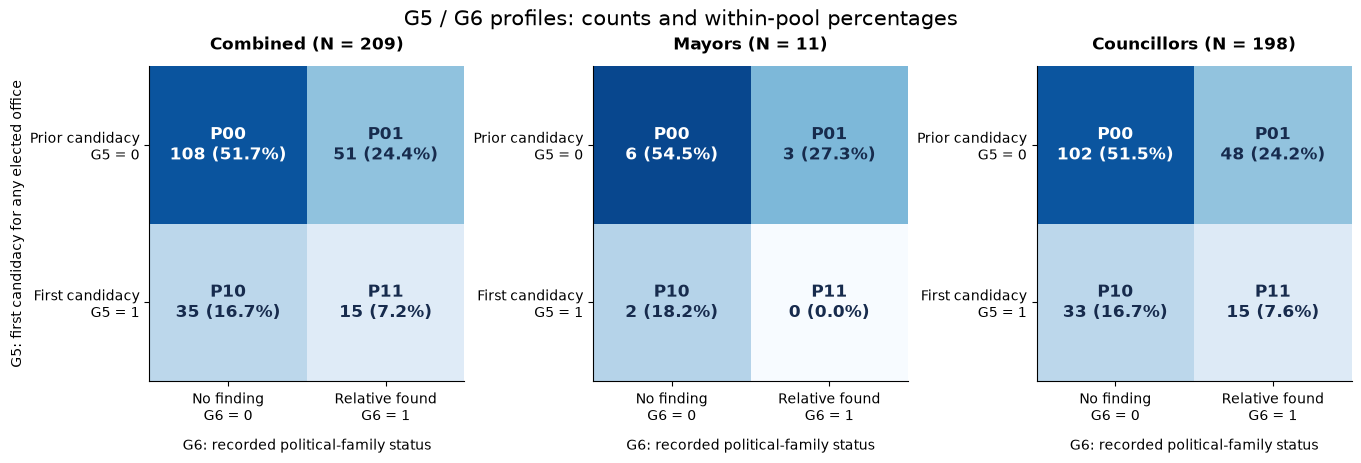

In [8]:
ASSET=ROOT/'finding/taipei_kaohsiung_g5_g6_clustering_20261108_assets'
ASSET.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,3,figsize=(13.5,4.5),constrained_layout=True)
for ax,pool in zip(axes,INPUTS):
    counts=profiles[profiles.pool==pool].set_index('profile_id').n
    ns=np.array([[counts['P00'],counts['P01']],[counts['P10'],counts['P11']]])
    perc=100*ns/len(prepared[pool])
    ax.imshow(perc,vmin=0,vmax=60,cmap='Blues',aspect='equal')
    for i in range(2):
        for j in range(2):
            pid=f'P{i}{j}'
            ax.text(j,i,f'{pid}\n{ns[i,j]} ({perc[i,j]:.1f}%)',ha='center',va='center',
                    color='white' if perc[i,j]>40 else '#172b4d',fontsize=12,fontweight='bold')
    ax.set_xticks([0,1],['No finding\nG6 = 0','Relative found\nG6 = 1'])
    ax.set_yticks([0,1],['Prior candidacy\nG5 = 0','First candidacy\nG5 = 1'])
    ax.set_xlabel('G6: recorded political-family status',labelpad=10)
    ax.set_ylabel('G5: first candidacy for any elected office' if pool=='all' else '')
    ax.set_title(f'{EN_POOL[pool]} (N = {len(prepared[pool])})',fontweight='bold',pad=12)
fig.suptitle('G5 / G6 profiles: counts and within-pool percentages',fontsize=15)
fig.savefig(ASSET/'profile_counts.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

圖1顯示各池四種組合的實際人數與池內百分比；顏色僅表示比例，0人格保留顯示，沒有新增空群。
三池最大群都是「曾參選／搜尋未發現公職親屬」，合併108人（51.7%）、首長6人（54.5%）、議員102人（51.5%）。
這是截至11/8資格審定版本內的觀察分布，不估計更大母體的平均值，故沒有加上不適用的平均值信賴區間。
圖中 No finding 指紀錄搜尋未發現，Relative found 指有符合定義的公職親屬，皆沿用既有編碼。

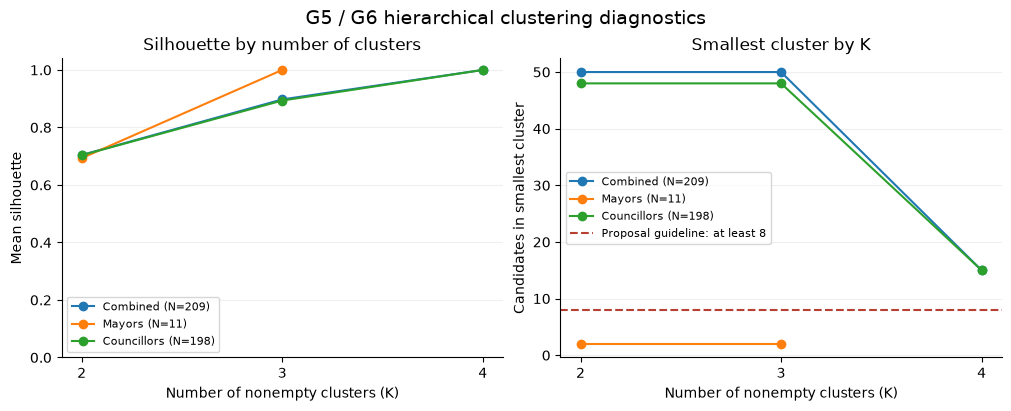

In [9]:
fig,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
for pool,g in diagnostics.groupby('pool',sort=False):
    label=f'{EN_POOL[pool]} (N={len(prepared[pool])})'
    axes[0].plot(g.requested_k,g.silhouette_mean,marker='o',label=label)
    axes[1].plot(g.requested_k,g.min_cluster_n,marker='o',label=label)
axes[0].set(title='Silhouette by number of clusters',xlabel='Number of nonempty clusters (K)',ylabel='Mean silhouette',ylim=(0,1.04))
axes[1].set(title='Smallest cluster by K',xlabel='Number of nonempty clusters (K)',ylabel='Candidates in smallest cluster')
axes[1].axhline(8,color='#b74032',linestyle='--',label='Proposal guideline: at least 8')
for ax in axes:
    ax.set_xticks([2,3,4]);ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2)
fig.suptitle('G5 / G6 hierarchical clustering diagnostics',fontsize=14)
fig.savefig(ASSET/'k_diagnostics.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

圖2比較不同K的分離度與最小群人數。最大的可用K只是保留全部不同組合；不能只看左圖silhouette=1就下實質類型結論。
首長池的群數與人數在右圖直接顯示其小樣本限制。較少K的合併結果需同時查看表6的列順序敏感度，不將其中一種並列解誤稱唯一分類。

In [10]:
# Save analysis outputs, then reopen the exact serialized files and verify every cell.
OUT=ROOT/'data/processed'
STEM='tk_g5_g6_'
SUFFIX='_20261108.csv'
outputs={f'{STEM}{pool}_assignments{SUFFIX}':d for pool,d in assignments.items()}
outputs.update({
 f'{STEM}profiles{SUFFIX}':profiles,
 f'{STEM}k_diagnostics{SUFFIX}':diagnostics,
 f'{STEM}alternative_assignments{SUFFIX}':alternative_assignments,
 f'{STEM}exclusions{SUFFIX}':exclusion_df,
 f'{STEM}order_sensitivity{SUFFIX}':order_check,
 f'{STEM}bootstrap{SUFFIX}':bootstrap,
})
manifest=[]
for filename,frame in outputs.items():
    path=OUT/filename
    frame.to_csv(path,index=False,encoding='utf-8-sig',float_format='%.12g')
    actual=pd.read_csv(path,dtype=str,keep_default_na=False)
    # Match serialized values, including the agreed 12-significant-digit float representation.
    from io import StringIO
    expected=pd.read_csv(StringIO(frame.to_csv(index=False,float_format='%.12g')),dtype=str,keep_default_na=False)
    pd.testing.assert_frame_equal(actual,expected)
    manifest.append({'path':str(path.relative_to(ROOT)),'rows':len(actual),'columns':list(actual.columns),
                     'sha256':sha(path),'verification':'saved CSV reopened; exact schema, row order and serialized cell equality'})
# Task-level checks on saved candidate assignments.
saved={pool:pd.read_csv(OUT/f'{STEM}{pool}_assignments{SUFFIX}',dtype=str,keep_default_na=False) for pool in INPUTS}
for pool,d in saved.items():
    assert d[KEY].is_unique and set(d[KEY])==set(prepared[pool][KEY])
    assert d[FEATURES].isin(['0','1']).all().all()
    assert (d.cluster_profile_id=='P'+d[FEATURES[0]]+d[FEATURES[1]]).all()
    assert d.clustering_pool.eq(pool).all()
    assert d.primary_silhouette.astype(float).between(-1,1).all()
assert set(saved['mayor'][KEY]).isdisjoint(saved['council'][KEY])
assert set(saved['mayor'][KEY])|set(saved['council'][KEY])==set(saved['all'][KEY])
for pool in ['mayor','council']:
    # Profile IDs, not arbitrary local alternative labels, agree across pools.
    lookup=saved['all'].set_index(KEY).cluster_profile_id
    assert saved[pool].cluster_profile_id.eq(saved[pool][KEY].map(lookup)).all()
for pool,spec in INPUTS.items(): assert sha(ROOT/spec['path'])==spec['sha256']
manifest_path=OUT/'tk_g5_g6_output_manifest_20261108.json'
manifest_path.write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
assert json.loads(manifest_path.read_text())==manifest
validation={
 'executed_date':'2026-11-08','analysis_features':FEATURES,
 'distance':'equal-weight symmetric categorical Gower = Hamming', 'linkage':'average',
 'primary_cut_distance':0,'primary_k':{p:f['k'] for p,f in fits.items()},
 'input_bindings':INPUTS,'sample':sample.to_dict('records'),
 'input_hashes_unchanged':True,'saved_csv_count':len(outputs),'saved_csv_readback':True,
 'unique_candidate_keys':True,'three_pool_partition':True,'cross_pool_profile_ids_agree':True,
 'primary_order_invariance_100_permutations':True,'bootstrap_replicates':BOOTSTRAPS,'seed':SEED,
 'mayor_minimum_size_guideline_passed':False,'G6_zero_means':'recorded search found no qualifying political relative',
 'versions':VERSIONS,
 'limitations':['Only two binary features; primary clusters exactly equal observed cross-tabulation profiles.',
                'Primary silhouette 1 is mechanical with replicated profiles, not external validation.',
                'Mayor N=11; cannot obtain 2 or more clusters each with at least 8 members.',
                'G6 coding may reflect unequal public information; retained provenance includes inferred and secondary-source cases.',
                'Current sample is the 2026-11-08 qualification-review snapshot, not a future finalized roster.']}
validation_path=OUT/'tk_g5_g6_validation_20261108.json'
validation_path.write_text(json.dumps(validation,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
assert json.loads(validation_path.read_text())==validation
print('PASS: 9 saved CSVs reopened; schema/cells/keys/partition/profiles and unchanged input hashes verified.')
display(pd.DataFrame(manifest)[['path','rows','sha256']].rename(columns={'path':'保存路徑','rows':'列數','sha256':'SHA-256'}))

PASS: 9 saved CSVs reopened; schema/cells/keys/partition/profiles and unchanged input hashes verified.


,保存路徑,列數,SHA-256
0,data/processed/tk_g5_g6_all_assignments_20261108.csv,209,f54b623ccced6a8d5b8fd5cbd264379f9d4c2be6451a2f05c88ed4772ad7309b
1,data/processed/tk_g5_g6_mayor_assignments_20261108.csv,11,1645b06697ea9d18c212e2712f882c8aba3ec5a83cf6d7df5ca5d57b1bcea8ee
2,data/processed/tk_g5_g6_council_assignments_20261108.csv,198,efa5c7af2d23a4565791a29612793af6863c5ceb71190529b91da34d4f93fd1a
3,data/processed/tk_g5_g6_profiles_20261108.csv,12,0077eda8bd3ea98313ed9add9c88a481bee966bce2ede6efd0ca3879b97dd75a
4,data/processed/tk_g5_g6_k_diagnostics_20261108.csv,8,4fbffc777b61760effe1e7e19aceaf5174c22ca7e06f6c1ec787c173f17d5081
5,data/processed/tk_g5_g6_alternative_assignments_20261108.csv,1243,33a2a83f62b49af55e79c77fd6dc027802f801a22ded166c222f7f1b424c6d70
6,data/processed/tk_g5_g6_exclusions_20261108.csv,0,23616373798de0eea548a35cb49f64ae4ddbbf0ce2ae59e8a4bcd71f730c4f1a
7,data/processed/tk_g5_g6_order_sensitivity_20261108.csv,8,b47c5869ece7910c89e02613d88b2e71361780d376e2ea78e4b511f4639f422e
8,data/processed/tk_g5_g6_bootstrap_20261108.csv,11,ebf933bb7c355b11eb8947c40a564106ebed985ba6818f952b5c3fb3b11e53c8


### 結果使用與限制

列順序重排100次中，主分群三池均100%一致；合併K=2／3僅61%／56%與基準分割相同，議員59%／51%，首長K=2為38%。
500次bootstrap中，首長P10（2人）整群未被抽到43次（8.6%），P01（3人）17次（3.4%）；合併及議員各主群皆在所有重抽中出現。這呈現小群涵蓋脆弱性，不是抽樣誤差的正式推論。

本Notebook已由clean kernel逐格執行並保存輸出；相同輸入SHA、固定排序與seed可重現。
[逐人分群及診斷的資料文件](../data/processed/tk_g5_g6_20261108_documentation.ipynb)逐檔固定輸出路徑與SHA；
[結果摘要](../report/taipei_kaohsiung_g5_g6_clustering_20261108.md)提供閱讀入口。

G6搜尋負值143人不等於已證明沒有公職親屬；正值也包括次級報導及已標記推論，分群沒有提升其證據等級。
本輪未重新查證候選人背景或更新未來正式名單。原本21位年齡缺值及15位教育政策fallback仍保留在上游，不影響只使用G5、G6的這次距離。
首長結果限描述，不能以小群直接推論後續策略差異。候選人的公職與縣市不參與分群；未混入年齡、性別、教育或黨派。

本地分析及驗證已完成；stage、commit、push依課程規則由學生自行進行，尚未提交。